In [1]:
from wildfire.data.io import load_csv, save_csv
from wildfire.enrichment.weather_batch import load_background_weather
from wildfire.enrichment.clc_enrichment import enrich_with_clc
from wildfire.data.ccaa import add_ccaa_budget_sums
from wildfire.geo.regions import assign_ccaa
from wildfire.processing.dedup_cross_sensor import apply_modeling_schema, collapse_cross_sensor_dupes
from wildfire.config import load_config
import numpy as np
import pandas as pd
import holidays
import matplotlib.pyplot as plt
from wildfire.processing.unsupervised import ID_COL, attach_id
from wildfire.processing.occurrence import (
    BACKGROUND_ID_COL,
    drop_leaking_background,
    occurrence_settings,
)
from wildfire.processing.pca_weather import AddWindCircular
from sklearn.preprocessing import StandardScaler


In [2]:

df = load_background_weather()
df = enrich_with_clc(df, country="Spain")
df = df[df["clc_class"] != 1]
df = add_ccaa_budget_sums(assign_ccaa(df))
df = apply_modeling_schema(
    collapse_cross_sensor_dupes(df)
)

num_years = load_config()["ccaa"]["budget_lookback_years"]
df = df.dropna(subset=["ccaa", "prevention_current", f"prevention_prev{num_years}", f"extinction_prev{num_years}"])

df.fillna({"boundary_layer_height": df["boundary_layer_height"].median()}, inplace=True)

display(df.isna().sum())

display(df)

C:\Projects\wildfires-project\src\wildfire\geo\regions.py:200: UserWarning: GeoJSON names without budget mapping: ['Ceuta', 'Melilla']; their budget sums will be NaN
  warnings.warn(


latitude                          0
longitude                         0
brightness                    97637
scan                          97637
acq_date                          0
acq_time                          0
brightness_ir                 97637
frp                           97637
daynight                          0
type                              0
year                              0
confidence_num                97637
confidence_cat                97637
temperature_2m                    0
precipitation                     0
surface_pressure                  0
relative_humidity_2m              0
wind_speed_10m                    0
wind_direction_10m                0
wind_gusts_10m                    0
rain                              0
et0_fao_evapotranspiration        0
shortwave_radiation               0
boundary_layer_height             0
is_day                            0
vapour_pressure_deficit           0
soil_moisture_0_to_7cm            0
soil_moisture_7_to_28cm     

,latitude,longitude,brightness,scan,acq_date,acq_time,brightness_ir,frp,daynight,type,...,clc_class_E,clc_class_NW,clc_class_NE,clc_class_SW,clc_class_SE,clc_uniform_surroundings,ccaa,prevention_current,prevention_prev3,extinction_prev3
0,39.2055,-4.3830,NaN,NaN,2023-03-07,306,NaN,NaN,N,0,...,7,7,7,7,7,True,Castilla-La Mancha,52.0,120.0,140.0
1,28.3190,-16.3628,NaN,NaN,2024-04-23,1309,NaN,NaN,D,0,...,9,9,9,9,9,True,Canarias,13.0,28.0,56.5
2,41.7144,-0.5928,NaN,NaN,2023-11-17,1249,NaN,NaN,D,0,...,9,9,9,9,9,True,Aragón,14.5,36.7,59.8
3,41.9930,-5.0063,NaN,NaN,2023-11-13,225,NaN,NaN,N,0,...,7,7,7,7,7,True,Castilla y León,60.0,79.0,129.0
4,40.0618,4.1329,NaN,NaN,2024-09-19,103,NaN,NaN,N,0,...,9,9,9,9,9,True,Islas Baleares,7.0,18.0,34.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97634,41.4259,-3.3286,NaN,NaN,2024-12-21,1256,NaN,NaN,D,0,...,5,6,5,6,5,False,Castilla y León,65.0,114.0,172.0
97635,40.4720,-6.7069,NaN,NaN,2023-01-13,149,NaN,NaN,N,0,...,6,6,6,6,6,True,Castilla y León,60.0,79.0,129.0
97636,42.9440,-3.2943,NaN,NaN,2024-02-24,1257,NaN,NaN,D,0,...,2,2,2,2,2,True,Castilla y León,65.0,114.0,172.0
97637,40.2354,-6.0920,NaN,NaN,2023-01-04,128,NaN,NaN,N,0,...,10,10,10,10,10,True,Extremadura,30.0,73.0,115.0


In [3]:
# DESCOMPOSICIÓN TEMPORAL
df['acq_date'] = pd.to_datetime(df['acq_date'])

df['month'] = df['acq_date'].dt.month
df['day_of_year'] = df['acq_date'].dt.dayofyear
df['es_fin_semana'] = df['acq_date'].dt.dayofweek.isin([5, 6]).astype(int)

# Segmentación de acq_time en tramos del día
df['acq_time_str'] = df['acq_time'].astype(str).str.zfill(4)
df['hora'] = pd.to_datetime(df['acq_time_str'], format='%H%M', errors='coerce').dt.hour

bins_hora = [-1, 6, 12, 18, 24]
labels_hora = ['Madrugada', 'Mañana', 'Tarde_Pico_Calor', 'Noche']
df['franja_horaria'] = pd.cut(df['hora'], bins=bins_hora, labels=labels_hora, right=False)

# Calcular festivos solo para combinaciones únicas de fecha/CCAA

# Festivos 
mapa_ccaa_holidays = {
    'Andalucía': 'AN', 'Aragón': 'AR', 'Asturias': 'AS', 'Islas Baleares': 'IB', 
    'Canarias': 'CN', 'Cantabria': 'CB', 'Castilla y León': 'CL', 
    'Castilla-La Mancha': 'CM', 'Cataluña': 'CT', 'Comunidad Valenciana': 'VC', 
    'Extremadura': 'EX', 'Galicia': 'GA', 'Madrid': 'MD', 
    'Región de Murcia': 'MC', 'Navarra': 'NC', 'País Vasco': 'PV', 'La Rioja': 'RI'
}

calendario_unico = df[['acq_date', 'ccaa']].dropna().drop_duplicates()

def evaluar_festivo(fila):
    codigo_region = mapa_ccaa_holidays.get(fila['ccaa'])
    if not codigo_region:
        return 0
    cal = holidays.Spain(years=fila['acq_date'].year, subdiv=codigo_region)
    return int(fila['acq_date'] in cal)

calendario_unico['es_festivo'] = calendario_unico.apply(evaluar_festivo, axis=1)

df = df.merge(calendario_unico, on=['acq_date', 'ccaa'], how='left')
df['es_festivo'] = df['es_festivo'].fillna(0).astype(int)

# Variable riesgo antrópico
df['riesgo_antropico_alto'] = ((df['es_fin_semana'] == 1) | (df['es_festivo'] == 1)).astype(int)

# Codificación cíclica con sin/cos

df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['day_of_year_sin'] = np.sin(2 * np.pi * df['day_of_year'] / 365.25)
df['day_of_year_cos'] = np.cos(2 * np.pi * df['day_of_year'] / 365.25)


In [4]:
# Hectáreas forestales (MITECO)

superficie_forestal_ha = {
    'Andalucía': 4400000, 'Aragón': 2600000, 'Asturias': 770000,
    'Islas Baleares': 220000, 'Canarias': 570000, 'Cantabria': 360000,
    'Castilla y León': 5100000, 'Castilla-La Mancha': 3600000, 'Cataluña': 2000000,
    'Comunidad Valenciana': 1300000, 'Extremadura': 2700000, 'Galicia': 2000000,
    'Madrid': 430000, 'Región de Murcia': 510000, 'Navarra': 610000,
    'País Vasco': 490000, 'La Rioja': 340000
}

df['sup_forestal_ha'] = df['ccaa'].map(superficie_forestal_ha)

df['ratio_prevencion_extincion'] = df[f'prevention_prev{num_years}'] / (df[f'extinction_prev{num_years}'] + 1e-5)
df['euros_prevencion_por_ha'] = (df[f'prevention_prev{num_years}'] * 1000000) / df['sup_forestal_ha']
df['euros_extincion_por_ha'] = (df[f'extinction_prev{num_years}'] * 1000000) / df['sup_forestal_ha']


# Potencial de secado atmosférico acelerado por el viento
df['potencial_propagacion'] = df['vapour_pressure_deficit'] * df['wind_speed_10m']

df['indice_riesgo_meteo'] = df['potencial_propagacion'] / (df['soil_moisture_0_to_7cm'] + 0.01)

df['estres_termico_vegetacion'] = df['temperature_2m'] / (df['relative_humidity_2m'] + 1)


df['indice_riesgo_meteo_log'] = np.log1p(df['indice_riesgo_meteo'])

# 7. Limpieza final
columnas_basura = [
    'acq_time_str', 'hora',
    'es_fin_semana', 'es_festivo'
]
df = df.drop(columns=columnas_basura)


Cobertura del índice: 100.0%


,indice_meteorologico
count,97637.000000
mean,50.000051
std,18.544806
min,2.883384
10%,25.766282
25%,35.085598
50%,49.138646
75%,64.635717
90%,76.128256
max,93.279162


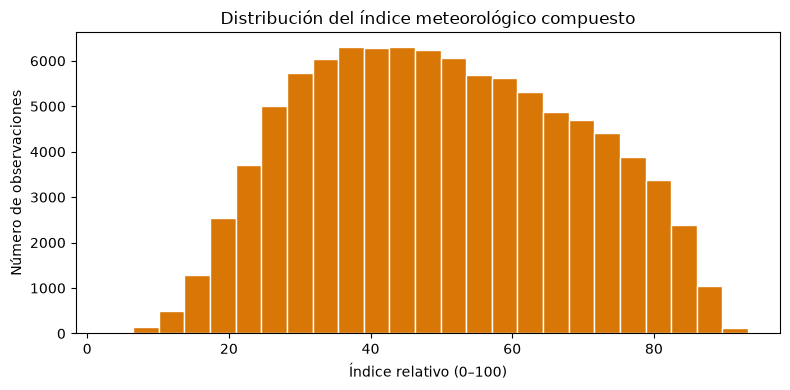

,observaciones,indice_medio,indice_mediano
ccaa,,,
Canarias,1227,60.880965,62.766651
Región de Murcia,2051,56.121308,55.665450
Andalucía,16291,54.913377,55.534044
Comunidad Valenciana,4378,54.716545,54.511533
Islas Baleares,888,54.348036,54.144228
Castilla-La Mancha,15219,53.719577,53.744508
Extremadura,7945,52.893126,52.963861
Aragón,9717,51.324852,50.806943
Madrid,1473,49.945360,49.191879


In [5]:
# peso y sentido del efecto en el peligro (True = un valor alto aumenta el score)
components = {
    'temperature_2m': {'weight': 0.20, 'higher_is_riskier': True},
    'relative_humidity_2m': {'weight': 0.20, 'higher_is_riskier': False},
    'wind_speed_10m': {'weight': 0.20, 'higher_is_riskier': True},
    'precipitation': {'weight': 0.15, 'higher_is_riskier': False},
    'vapour_pressure_deficit': {'weight': 0.15, 'higher_is_riskier': True},
    'soil_moisture_0_to_7cm': {'weight': 0.10, 'higher_is_riskier': False},
}
assert np.isclose(sum(v['weight'] for v in components.values()), 1.0)

risk_subscores = pd.DataFrame(index=df.index)
for col, spec in components.items():
    percentile = df[col].rank(method='average', pct=True)
    risk_subscores[col + '_risk_pct'] = percentile if spec['higher_is_riskier'] else 1 - percentile

weights = pd.Series({col + '_risk_pct': spec['weight'] for col, spec in components.items()})
available_weight = risk_subscores.notna().mul(weights).sum(axis=1)
weighted_score = risk_subscores.mul(weights, axis='columns').sum(axis=1, min_count=1) / available_weight
components_available = risk_subscores.notna().sum(axis=1)
df['indice_meteorologico'] = (weighted_score * 100).where(components_available >= 4)
df['componentes_disponibles'] = components_available
df['nivel_relativo'] = pd.cut(df['indice_meteorologico'], bins=[-0.001, 100/3, 200/3, 100], labels=['Bajo', 'Medio', 'Alto'], include_lowest=True)

print('Cobertura del índice:', f"{df['indice_meteorologico'].notna().mean():.1%}")
df[['indice_meteorologico', 'componentes_disponibles', 'nivel_relativo']].describe(include='all')

display(df['indice_meteorologico'].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame())
ax = df['indice_meteorologico'].dropna().plot(kind='hist', bins=25, figsize=(8, 4), color='#d97706', edgecolor='white')
ax.set(title='Distribución del índice meteorológico compuesto', xlabel='Índice relativo (0–100)', ylabel='Número de observaciones')
plt.tight_layout()
plt.show()

if 'ccaa' in df.columns:
    resumen_ccaa = (df.groupby('ccaa', dropna=False)
                    .agg(observaciones=('indice_meteorologico', 'count'),
                         indice_medio=('indice_meteorologico', 'mean'),
                         indice_mediano=('indice_meteorologico', 'median'))
                    .sort_values('indice_medio', ascending=False))
    display(resumen_ccaa)

# Clave estable del bloque 03: orden de filas de `wildfire_data_cleaned.csv`.
# 03a la copia tal cual (el orden manda, no la posición).
df = attach_id(df)

In [6]:
# La dirección cruda es circular (359° ~ 1°): se expande a wd_sin/wd_cos
# como en el PCA; la cruda queda fuera de todo lo que sigue.
_wd = AddWindCircular().fit_transform(df[["wind_direction_10m"]])
df[["wd_sin", "wd_cos"]] = _wd

# Columnas satelitales (todas nulas en el fondo) que occurrence.py veta;
# rain/is_day/type se conservan (el contrato los permite).
satellite_drop = [
    'brightness', 'scan', 'brightness_ir', 'frp',
    'confidence_num', 'confidence_cat',
]
df = df.drop(columns=[c for c in satellite_drop if c in df.columns])

# Clave del fondo: `background_id` (entero único), como espera load_background_days.
df = df.rename(columns={ID_COL: BACKGROUND_ID_COL})

# Sin fugas: fuera las filas a <= leakage_max_km de una detección del mismo día.
positives = load_csv('data/processed/expanded/firms_spain_final_lags_index.csv')
before = len(df)
df = drop_leaking_background(
    df, positives, leakage_max_km=occurrence_settings()['leakage_max_km']
)
print(f'Filas: {before:,} -> {len(df):,} (fugas eliminadas: {before - len(df)})')
print('Columnas:', len(df.columns))
df.head()


Filas: 97,637 -> 97,630 (fugas eliminadas: 7)
Columnas: 58


,background_id,latitude,longitude,acq_date,acq_time,daynight,type,year,temperature_2m,precipitation,...,euros_extincion_por_ha,potencial_propagacion,indice_riesgo_meteo,estres_termico_vegetacion,indice_riesgo_meteo_log,indice_meteorologico,componentes_disponibles,nivel_relativo,wd_sin,wd_cos
0,0,39.2055,-4.3830,2023-03-07,306,N,0,2023,9.280000,0.01,...,38.888889,1.116132,7.966682,0.096634,2.193516,37.483638,6,Medio,-0.922157,-0.386817
1,1,28.3190,-16.3628,2024-04-23,1309,D,0,2024,22.855999,0.00,...,99.122807,13.626798,64.368433,0.315024,4.180039,67.503943,6,Alto,0.983868,0.178896
2,2,41.7144,-0.5928,2023-11-17,1249,D,0,2023,15.775833,0.00,...,23.000000,22.348605,119.917397,0.266254,4.795108,68.905820,6,Alto,-0.890304,0.455367
3,3,41.9930,-5.0063,2023-11-13,225,N,0,2023,14.120833,0.00,...,25.294118,2.632770,8.632034,0.150677,2.265094,47.225104,6,Medio,-0.538943,-0.842342
4,4,40.0618,4.1329,2024-09-19,103,N,0,2024,17.905000,0.00,...,156.818182,4.889784,80.160396,0.233456,4.396427,59.356212,6,Medio,0.740820,0.671704


In [7]:
# Fondo en unidades crudas, igual que firms_spain_final_lags_index.csv.
# El escalado es responsabilidad del pliegue (notebook 04), no del artefacto.
output_path = 'data/processed/expanded/background_days.csv'
save_csv(df, output_path)
print(f'Fondo crudo guardado en: {output_path}')


Fondo crudo guardado en: data/processed/expanded/background_days.csv


In [8]:
# Copia descriptiva normalizada (solo EDA): NUNCA entra en el modelado.
# Se excluyen id, bandera binaria y códigos; grados y seno/coseno sin escalar.
exclude = {'background_id', 'riesgo_antropico_alto', 'type', 'acq_time',
           'is_day', 'year', 'month', 'day_of_year', 'componentes_disponibles',
           'indice_meteorologico', 'nivel_relativo', 'rain', 'wind_direction_10m'}
exclude.update(c for c in df.columns if c.lower().startswith('clc_'))
numeric_cols = [
    c for c in df.select_dtypes(include=[np.number]).columns
    if c not in exclude and not pd.api.types.is_bool_dtype(df[c])
]
UNSCALED = {'latitude', 'longitude', 'month_sin', 'month_cos',
            'day_of_year_sin', 'day_of_year_cos', 'wd_sin', 'wd_cos'}
scale_cols = [c for c in numeric_cols if c not in UNSCALED]
if not scale_cols:
    raise ValueError('No se encontraron variables numéricas continuas para normalizar.')
df_norm = df.copy()
df_norm[scale_cols] = StandardScaler().fit_transform(df[scale_cols])
norm_path = 'data/processed/expanded/background_days_normalized.csv'
save_csv(df_norm, norm_path)
print(f'Copia normalizada (EDA) guardada en: {norm_path}')


Copia normalizada (EDA) guardada en: data/processed/expanded/background_days_normalized.csv
